In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("kidney_disease.csv")

In [3]:
df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [4]:
df.shape

(400, 26)

In [5]:
df.columns

Index(['id', 'age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr',
       'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad',
       'appet', 'pe', 'ane', 'classification'],
      dtype='object')

In [6]:
df['classification'].value_counts()

classification
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              400 non-null    int64  
 1   age             391 non-null    float64
 2   bp              388 non-null    float64
 3   sg              353 non-null    float64
 4   al              354 non-null    float64
 5   su              351 non-null    float64
 6   rbc             248 non-null    object 
 7   pc              335 non-null    object 
 8   pcc             396 non-null    object 
 9   ba              396 non-null    object 
 10  bgr             356 non-null    float64
 11  bu              381 non-null    float64
 12  sc              383 non-null    float64
 13  sod             313 non-null    float64
 14  pot             312 non-null    float64
 15  hemo            348 non-null    float64
 16  pcv             330 non-null    object 
 17  wc              295 non-null    obj

In [8]:
df.isnull().sum()

id                  0
age                 9
bp                 12
sg                 47
al                 46
su                 49
rbc               152
pc                 65
pcc                 4
ba                  4
bgr                44
bu                 19
sc                 17
sod                87
pot                88
hemo               52
pcv                70
wc                105
rc                130
htn                 2
dm                  2
cad                 2
appet               1
pe                  1
ane                 1
classification      0
dtype: int64

for numerical data use mean and median and for categorical data use mode

In [9]:
from sklearn.impute import SimpleImputer

In [10]:
mode=SimpleImputer(missing_values=np.nan,strategy='most_frequent')

df_imputer=pd.DataFrame(mode.fit_transform(df))
df_imputer.columns=df.columns
df_imputer

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.02,1.0,0.0,normal,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.02,4.0,0.0,normal,normal,notpresent,notpresent,...,38,6000,5.2,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.01,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,5.2,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.01,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395,55.0,80.0,1.02,0.0,0.0,normal,normal,notpresent,notpresent,...,47,6700,4.9,no,no,no,good,no,no,notckd
396,396,42.0,70.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,54,7800,6.2,no,no,no,good,no,no,notckd
397,397,12.0,80.0,1.02,0.0,0.0,normal,normal,notpresent,notpresent,...,49,6600,5.4,no,no,no,good,no,no,notckd
398,398,17.0,60.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,...,51,7200,5.9,no,no,no,good,no,no,notckd


In [11]:
df_imputer.isnull().sum()

id                0
age               0
bp                0
sg                0
al                0
su                0
rbc               0
pc                0
pcc               0
ba                0
bgr               0
bu                0
sc                0
sod               0
pot               0
hemo              0
pcv               0
wc                0
rc                0
htn               0
dm                0
cad               0
appet             0
pe                0
ane               0
classification    0
dtype: int64

find the unique data

In [12]:
set(df_imputer['age'].to_list())

{2.0,
 3.0,
 4.0,
 5.0,
 6.0,
 7.0,
 8.0,
 11.0,
 12.0,
 14.0,
 15.0,
 17.0,
 19.0,
 20.0,
 21.0,
 22.0,
 23.0,
 24.0,
 25.0,
 26.0,
 27.0,
 28.0,
 29.0,
 30.0,
 32.0,
 33.0,
 34.0,
 35.0,
 36.0,
 37.0,
 38.0,
 39.0,
 40.0,
 41.0,
 42.0,
 43.0,
 44.0,
 45.0,
 46.0,
 47.0,
 48.0,
 49.0,
 50.0,
 51.0,
 52.0,
 53.0,
 54.0,
 55.0,
 56.0,
 57.0,
 58.0,
 59.0,
 60.0,
 61.0,
 62.0,
 63.0,
 64.0,
 65.0,
 66.0,
 67.0,
 68.0,
 69.0,
 70.0,
 71.0,
 72.0,
 73.0,
 74.0,
 75.0,
 76.0,
 78.0,
 79.0,
 80.0,
 81.0,
 82.0,
 83.0,
 90.0}

In [13]:
for i in df_imputer.columns:
    print("***********",i,"************")
    print()
    print(df_imputer[i].to_list())
    print()

*********** id ************

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 

In [14]:
print(df_imputer['rc'].mode())
print(df_imputer['wc'].mode())
print(df_imputer['pcv'].mode())

0    5.2
Name: rc, dtype: object
0    9800
Name: wc, dtype: object
0    41
Name: pcv, dtype: object


In [15]:
df_imputer['classification']=df_imputer['classification'].apply(lambda x:'ckd' if x=='ckd\t' else x)
df_imputer['cad']=df_imputer['cad'].apply(lambda x:'no' if x=='\tno' else x)
df_imputer['dm']=df_imputer['dm'].apply(lambda x:'no' if x=='\tno' else x)
df_imputer['dm']=df_imputer['dm'].apply(lambda x:'yes' if x=='\tyes' else x)
df_imputer['dm']=df_imputer['dm'].apply(lambda x:'yes' if x=='yes' else x)

df_imputer['rc']=df_imputer['rc'].apply(lambda x:'5.2' if x=='\t?' else x)

df_imputer['wc']=df_imputer['wc'].apply(lambda x:'9800' if x=='\t6200' else x)
df_imputer['wc']=df_imputer['wc'].apply(lambda x:'9800' if x=='\t8400' else x)
df_imputer['wc']=df_imputer['wc'].apply(lambda x:'9800' if x=='\t?' else x)

df_imputer['pcv']=df_imputer['pcv'].apply(lambda x:'41' if x=='\t43' else x)
df_imputer['pcv']=df_imputer['pcv'].apply(lambda x:'41' if x=='\t?' else x)

In [16]:
df_imputer['classification'].value_counts()

classification
ckd       250
notckd    150
Name: count, dtype: int64

<IPython.core.display.Javascript object>

Axes(0.125,0.11;0.775x0.77)


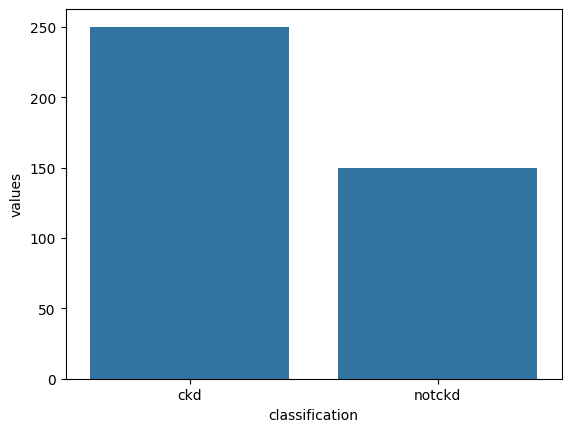

In [17]:
temp=df_imputer['classification'].value_counts()
temp_df=pd.DataFrame({'classification':temp.index,'values':temp.values})
print(sns.barplot(x='classification',y='values',data=temp_df))

In [18]:
df_imputer.dtypes

id                object
age               object
bp                object
sg                object
al                object
su                object
rbc               object
pc                object
pcc               object
ba                object
bgr               object
bu                object
sc                object
sod               object
pot               object
hemo              object
pcv               object
wc                object
rc                object
htn               object
dm                object
cad               object
appet             object
pe                object
ane               object
classification    object
dtype: object

In [19]:
df.select_dtypes(exclude=['object']).columns

Index(['id', 'age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot',
       'hemo'],
      dtype='object')

In [20]:
for i in df.select_dtypes(exclude=['object']).columns:
    df_imputer[i]=df_imputer[i].apply(lambda x:float(x))

In [21]:
df_imputer.dtypes

id                float64
age               float64
bp                float64
sg                float64
al                float64
su                float64
rbc                object
pc                 object
pcc                object
ba                 object
bgr               float64
bu                float64
sc                float64
sod               float64
pot               float64
hemo              float64
pcv                object
wc                 object
rc                 object
htn                object
dm                 object
cad                object
appet              object
pe                 object
ane                object
classification     object
dtype: object

In [22]:
import seaborn as sns

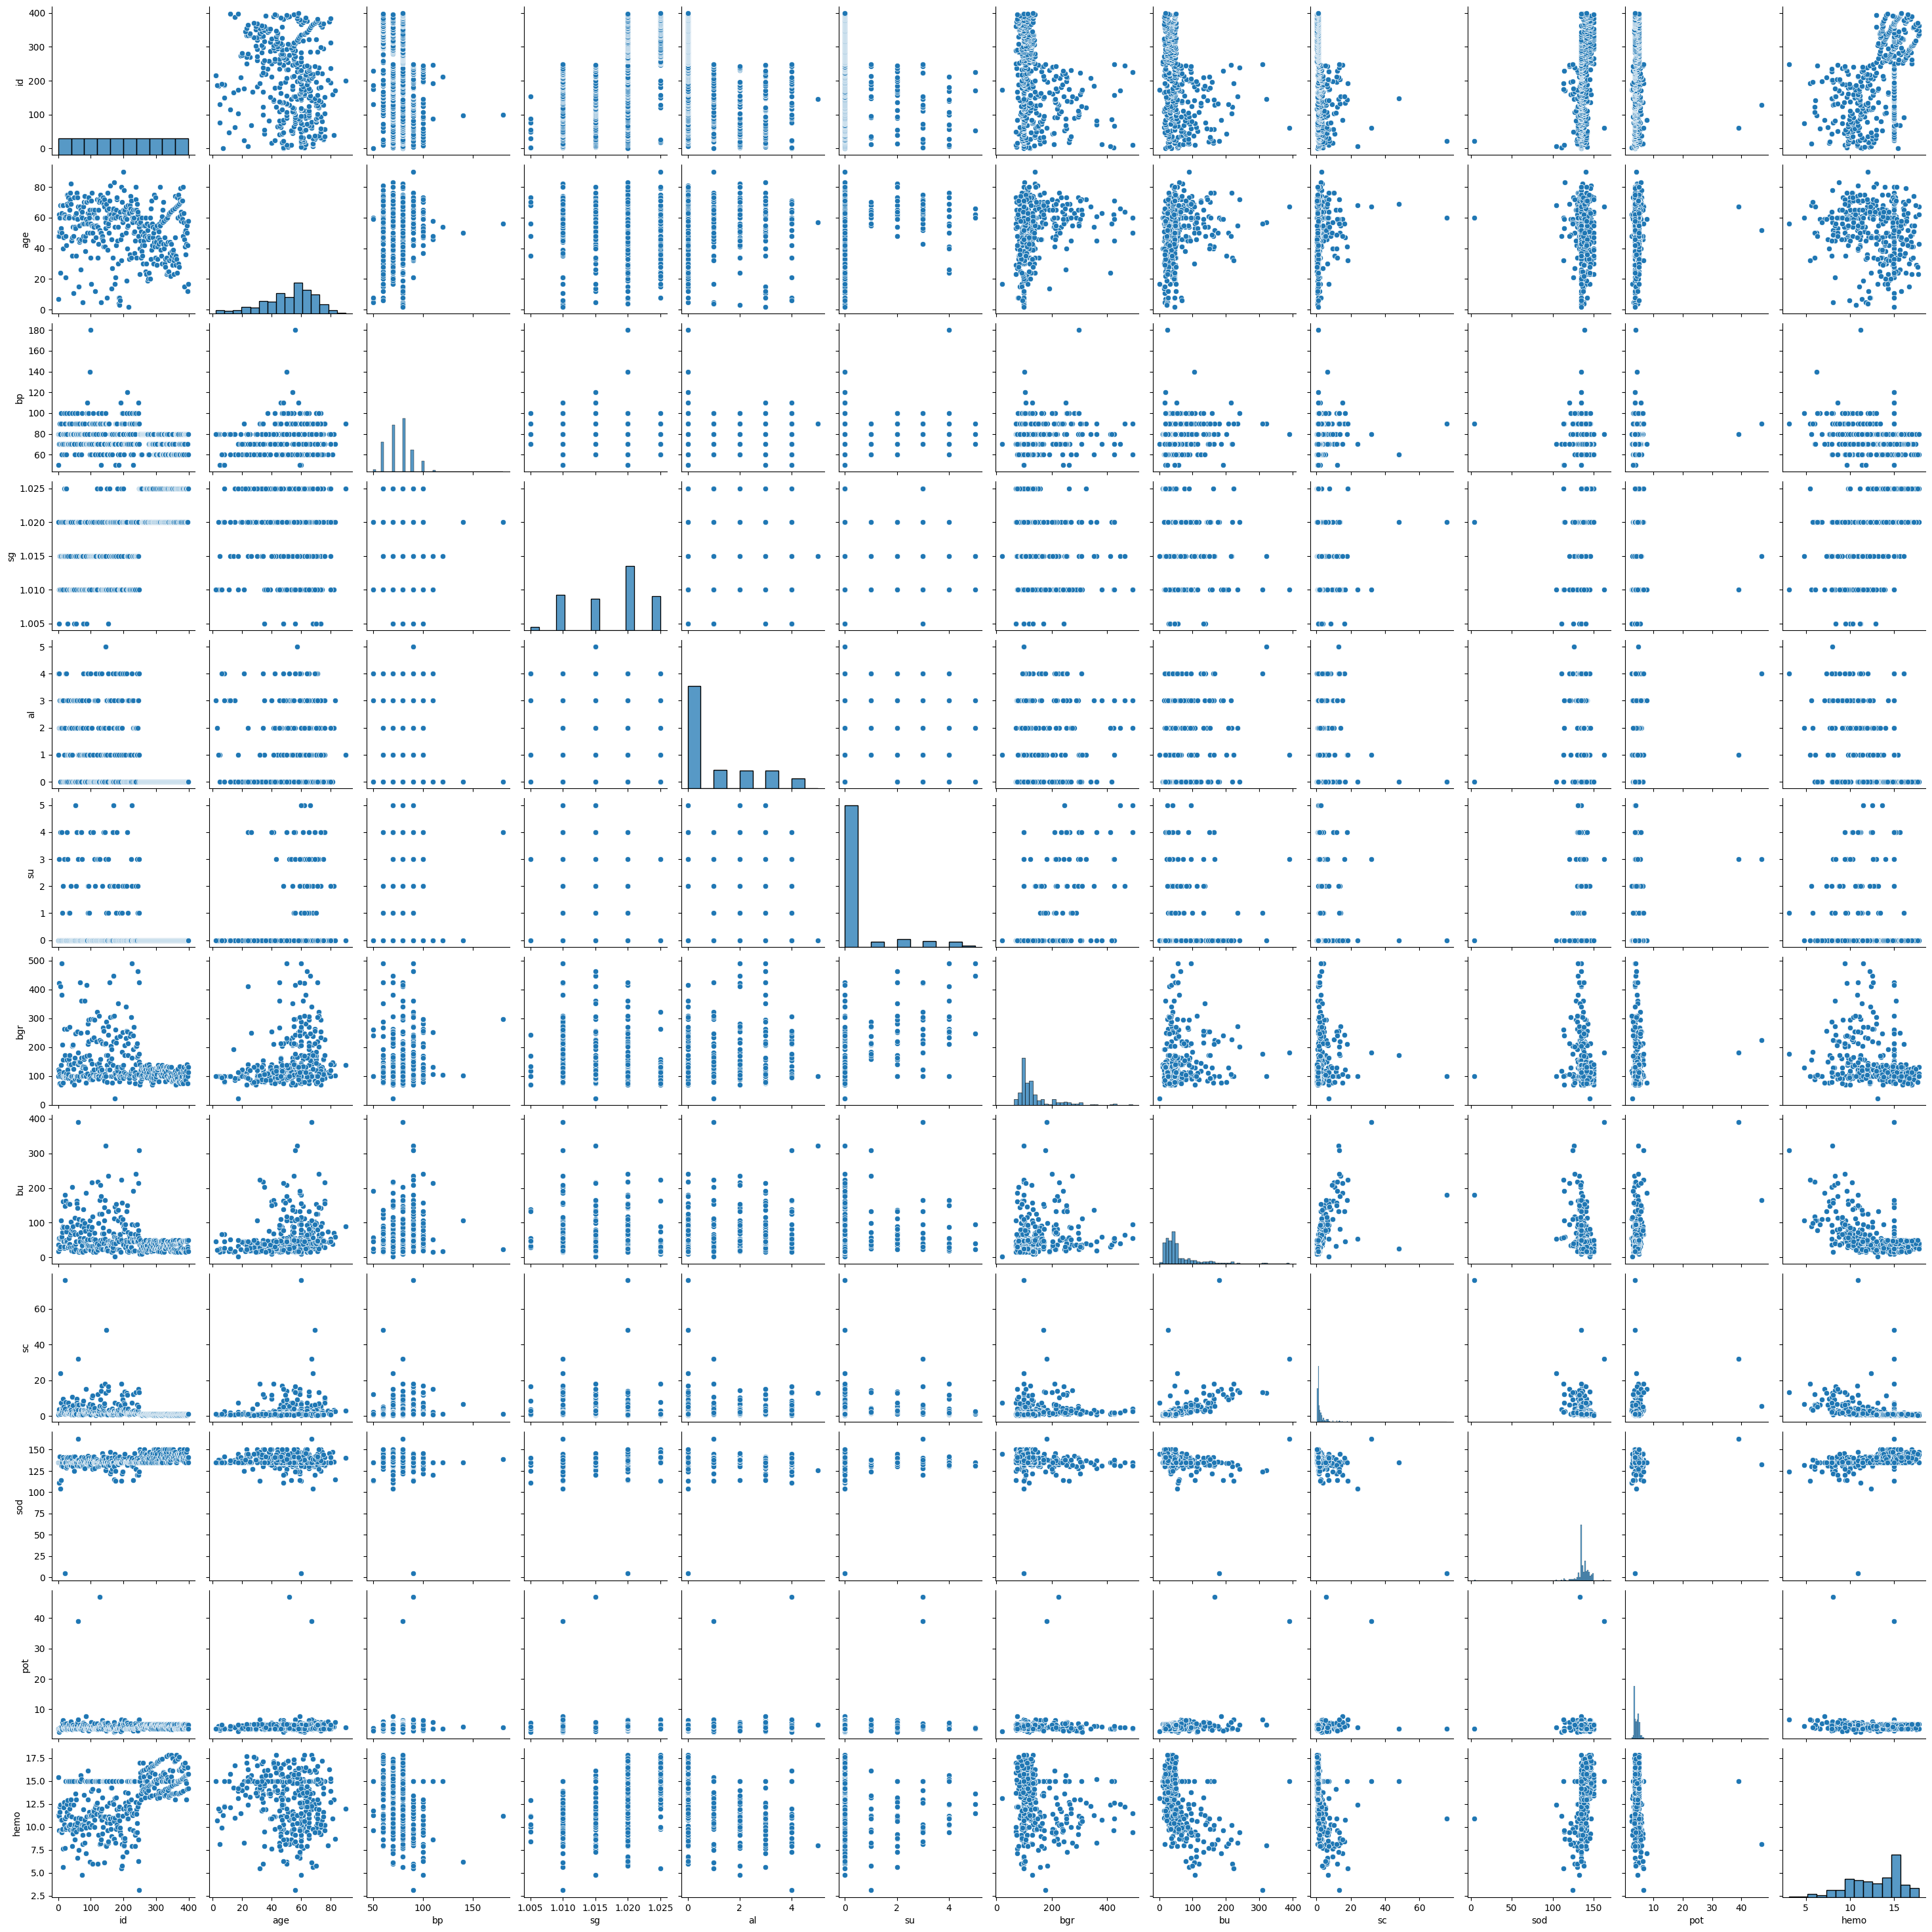

In [23]:
sns.pairplot(df_imputer)

<IPython.core.display.Javascript object>

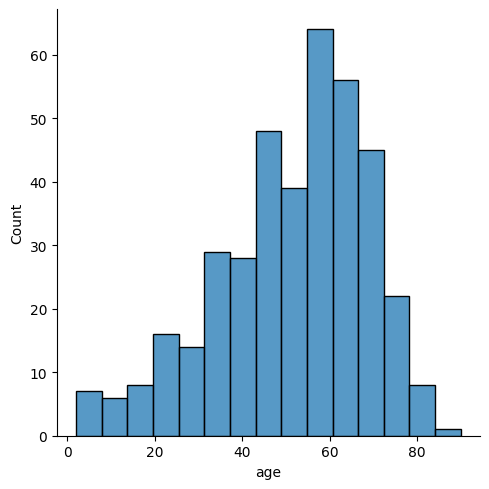

<IPython.core.display.Javascript object>

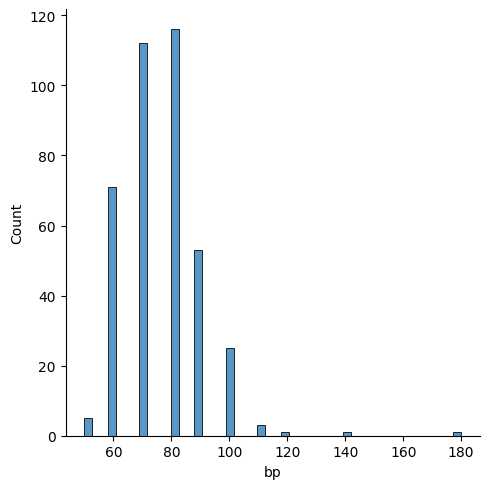

<IPython.core.display.Javascript object>

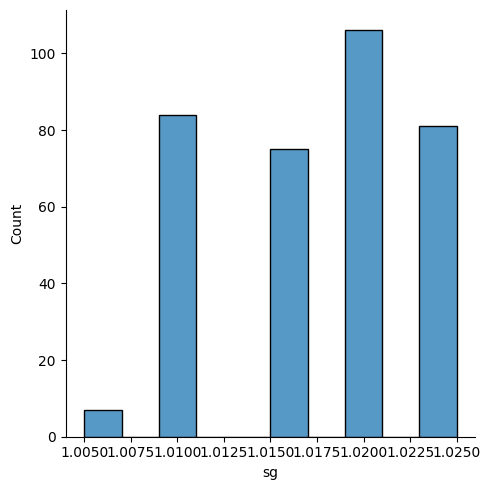

<IPython.core.display.Javascript object>

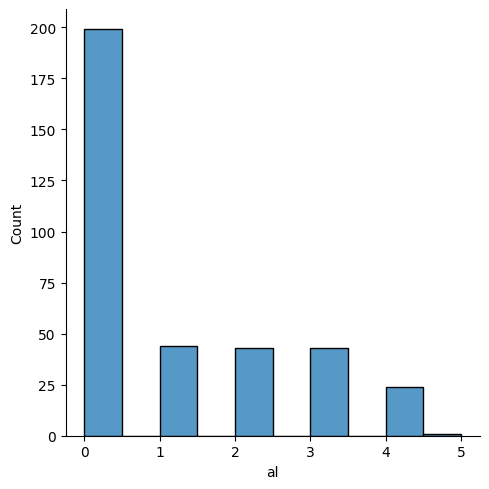

<IPython.core.display.Javascript object>

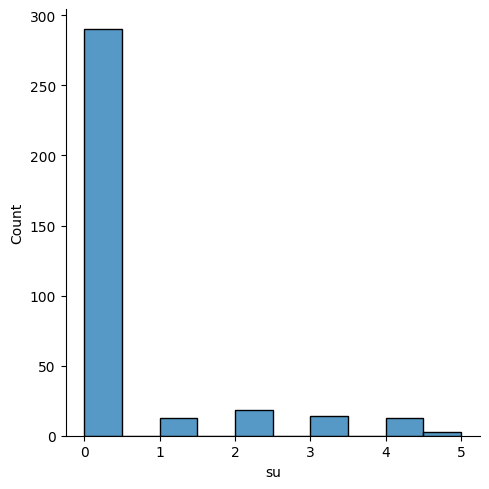

<IPython.core.display.Javascript object>

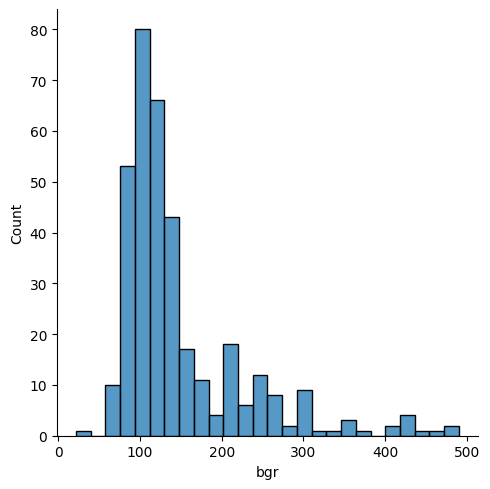

<IPython.core.display.Javascript object>

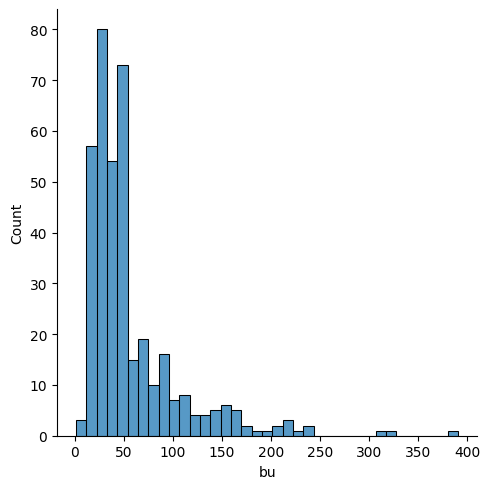

<IPython.core.display.Javascript object>

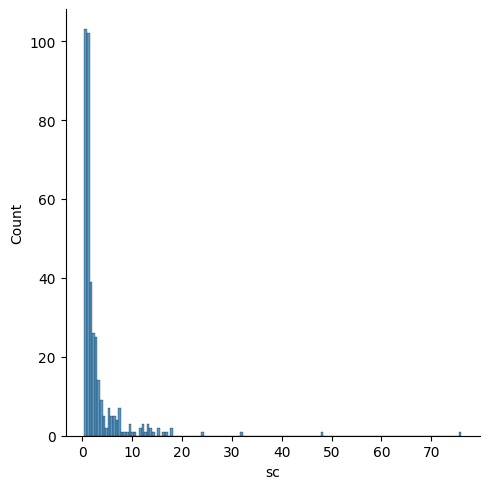

<IPython.core.display.Javascript object>

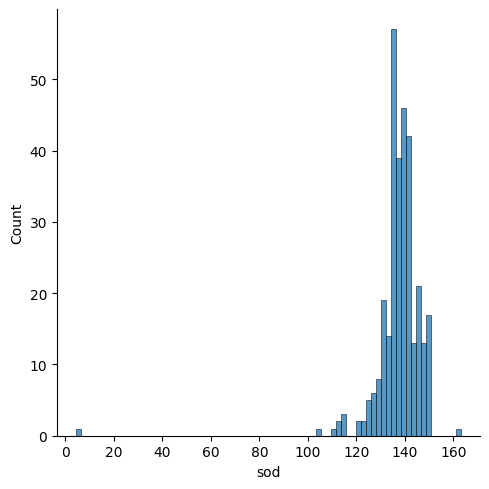

<IPython.core.display.Javascript object>

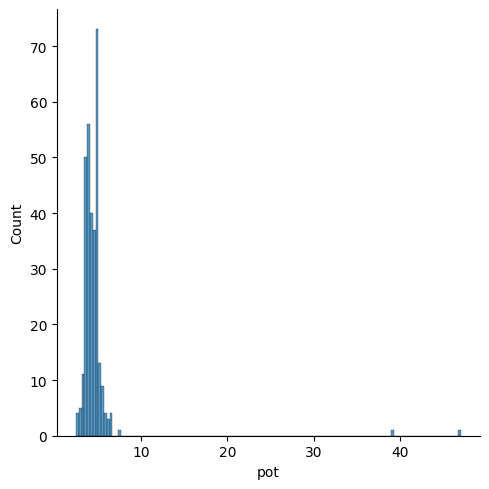

<IPython.core.display.Javascript object>

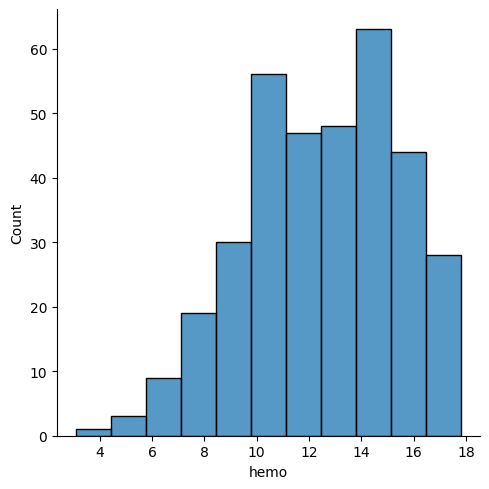

In [24]:
def distplots(col):
    sns.displot(df[col])
    plt.show()

for i in list(df_imputer.select_dtypes(exclude=['object']).columns)[1:]:
    distplots(i)

outliers detection and remove

<IPython.core.display.Javascript object>

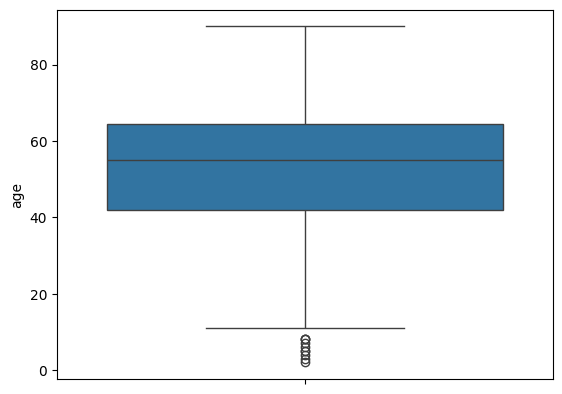

<IPython.core.display.Javascript object>

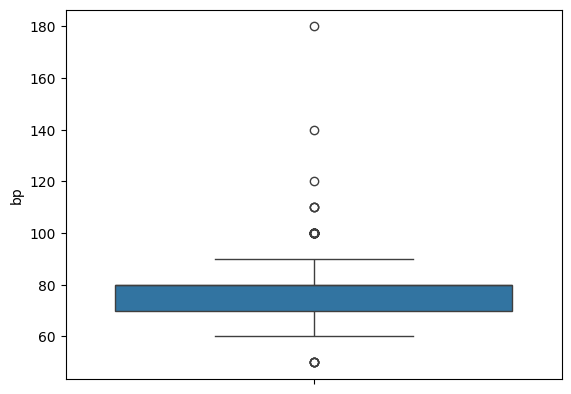

<IPython.core.display.Javascript object>

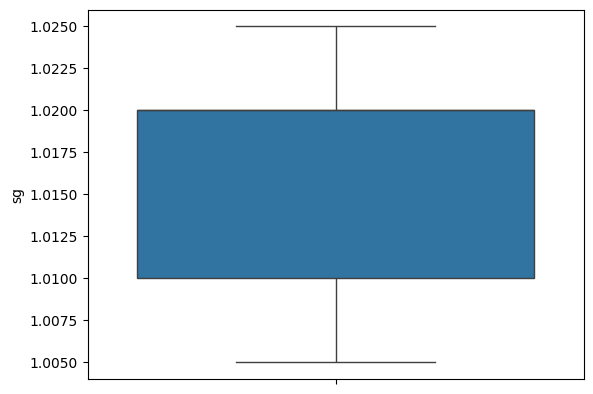

<IPython.core.display.Javascript object>

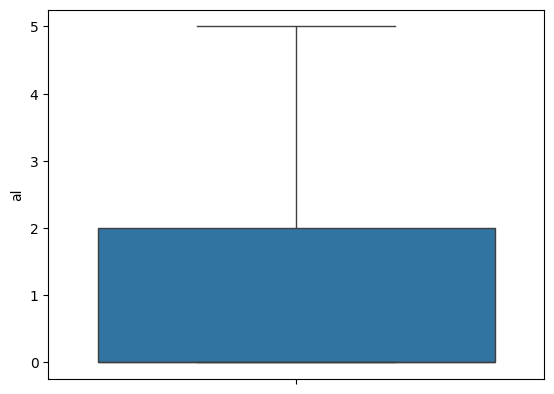

<IPython.core.display.Javascript object>

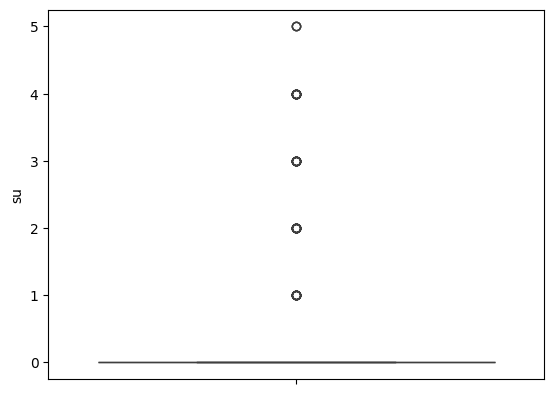

<IPython.core.display.Javascript object>

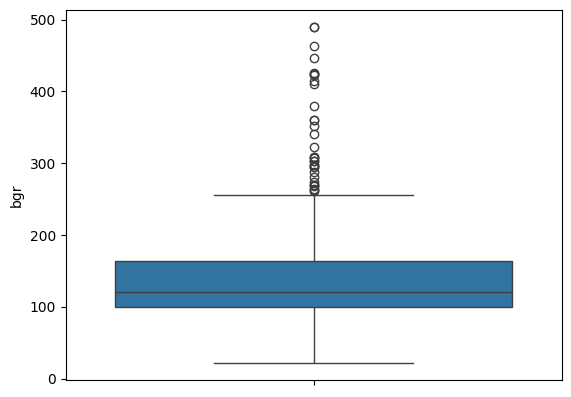

<IPython.core.display.Javascript object>

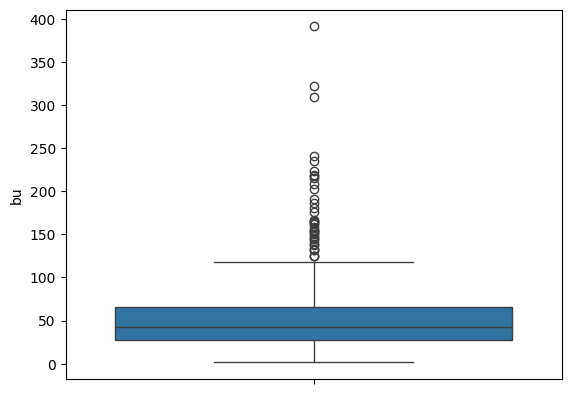

<IPython.core.display.Javascript object>

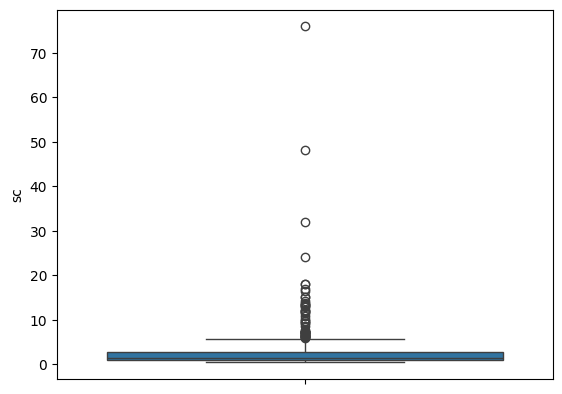

<IPython.core.display.Javascript object>

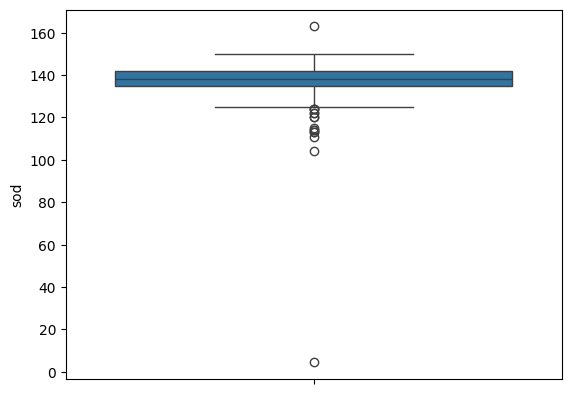

<IPython.core.display.Javascript object>

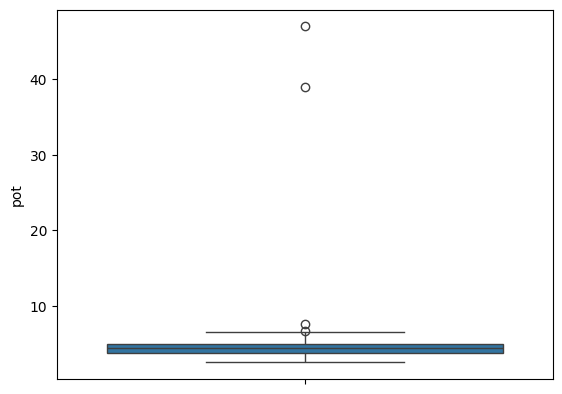

<IPython.core.display.Javascript object>

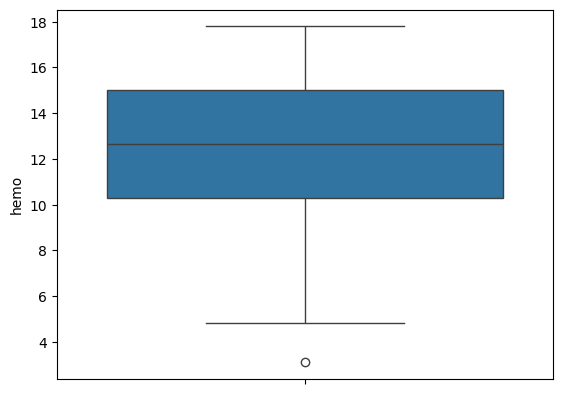

In [25]:
def boxf(col):
    sns.boxplot(df[col])
    plt.show()

for i in list(df_imputer.select_dtypes(exclude=['object']).columns)[1:]:
    boxf(i)

In [26]:
df_imputer.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0.0,48.0,80.0,1.020,1.0,0.0,normal,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1.0,7.0,50.0,1.020,4.0,0.0,normal,normal,notpresent,notpresent,...,38,6000,5.2,no,no,no,good,no,no,ckd
2,2.0,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,5.2,no,yes,no,poor,no,yes,ckd
3,3.0,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4.0,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [27]:
from sklearn import preprocessing


In [28]:
encode=df_imputer.apply(preprocessing.LabelEncoder().fit_transform)
encode

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,40,3,3,1,0,1,1,0,0,...,30,69,30,1,2,0,0,0,0,0
1,1,5,0,3,4,0,1,1,0,0,...,24,53,30,0,1,0,0,0,0,0
2,2,54,3,1,2,3,1,1,0,0,...,17,67,30,0,2,0,1,0,1,0
3,3,40,2,0,4,0,1,0,1,0,...,18,59,17,1,1,0,1,1,1,0
4,4,43,3,1,2,0,1,1,0,0,...,21,65,24,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,395,47,3,3,0,0,1,1,0,0,...,33,59,27,0,1,0,0,0,0,1
396,396,34,2,4,0,0,1,1,0,0,...,40,69,40,0,1,0,0,0,0,1
397,397,8,3,3,0,0,1,1,0,0,...,35,58,32,0,1,0,0,0,0,1
398,398,11,1,4,0,0,1,1,0,0,...,37,64,37,0,1,0,0,0,0,1


In [29]:
encode.to_csv("Final_pre_processing_data.csv")

In [30]:
import matplotlib.pyplot as plt

<Axes: >

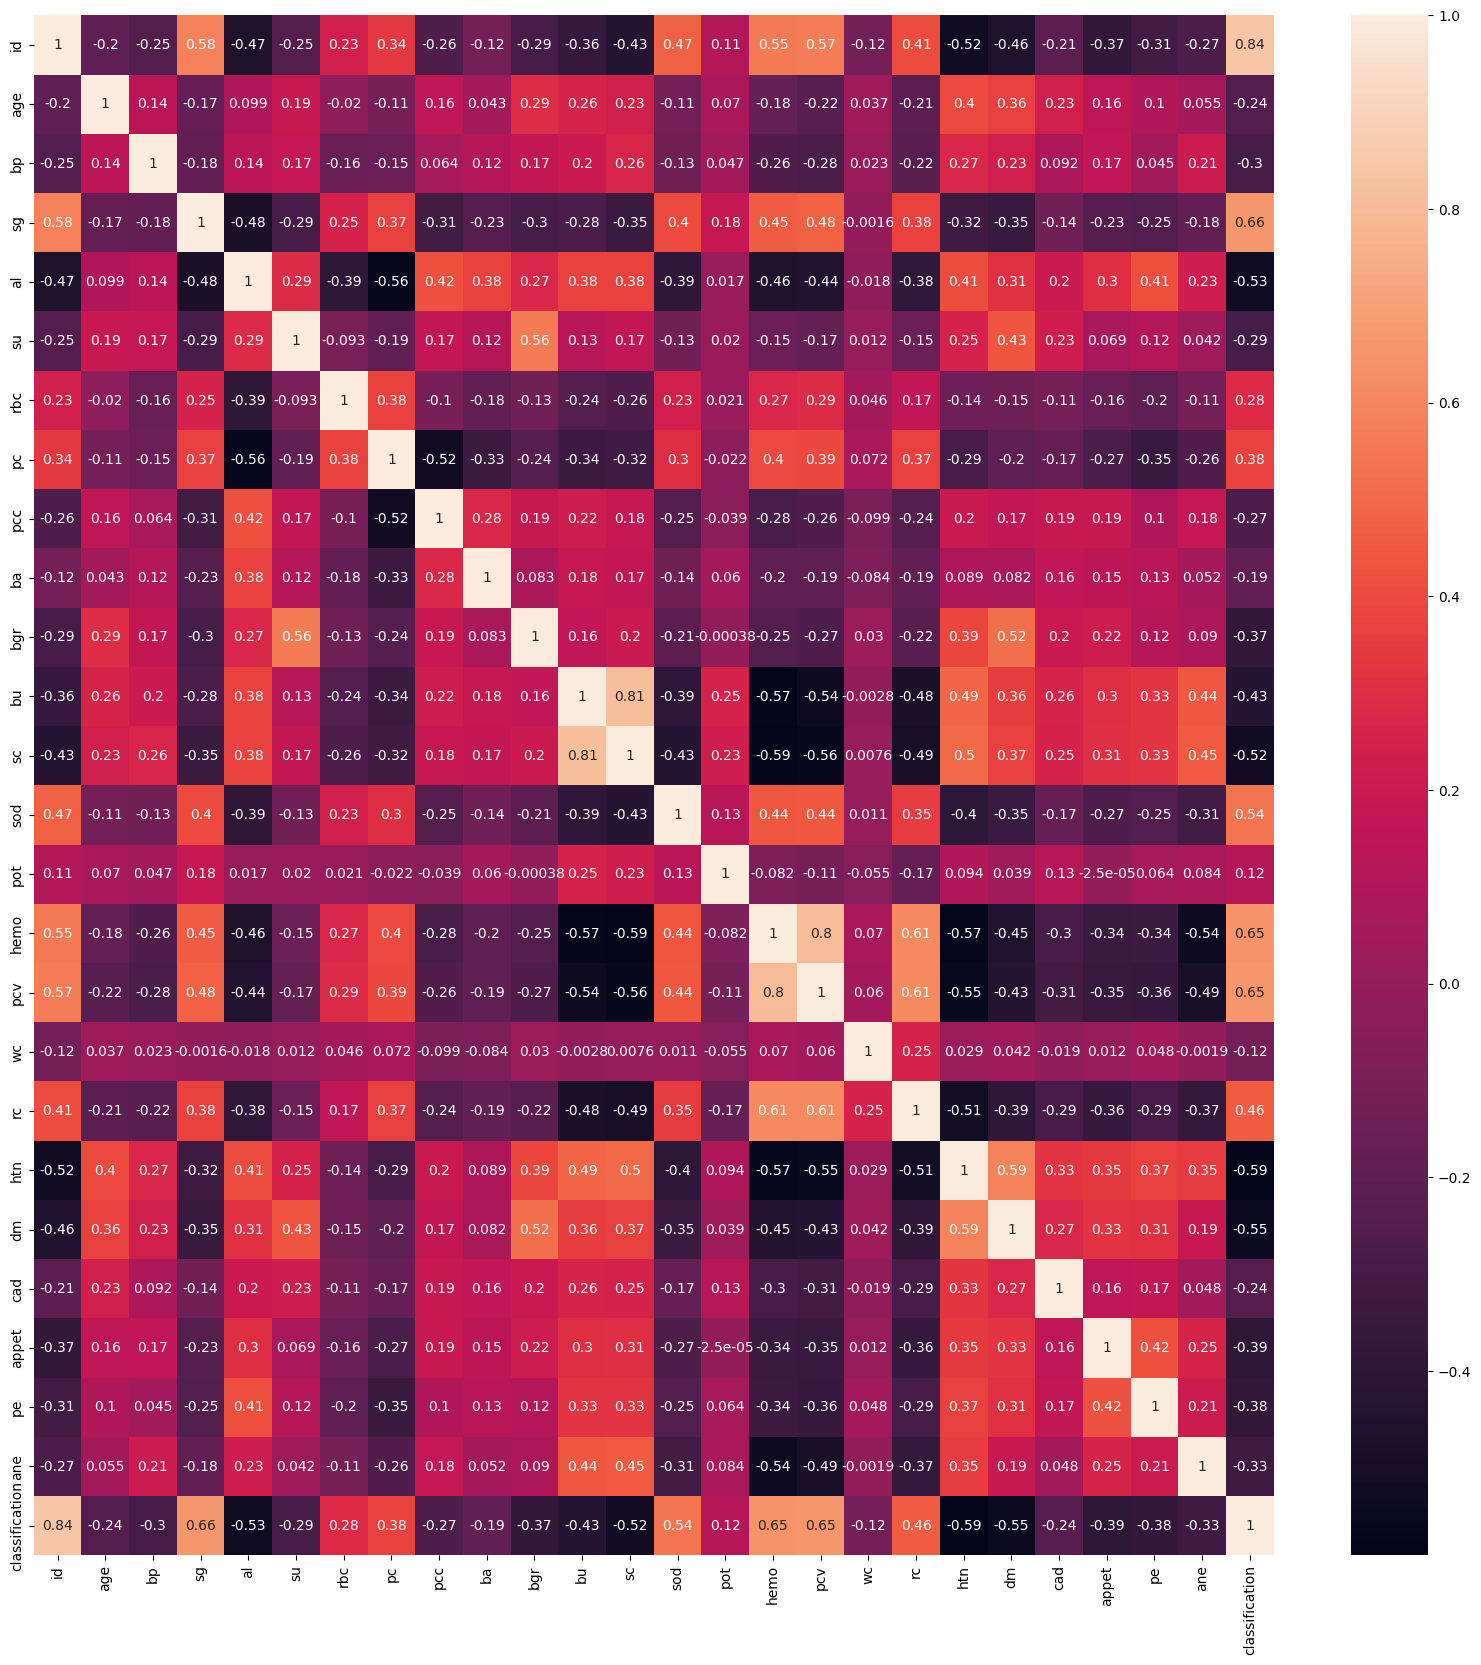

In [31]:
plt.figure(figsize=(20,20))
corr=encode.corr()
sns.heatmap(corr,annot=True)

In [32]:
x = encode.drop(['id','classification'], axis=1, errors='ignore')
y = encode['classification']

In [33]:
x.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,hemo,pcv,wc,rc,htn,dm,cad,appet,pe,ane
0,40,3,3,1,0,1,1,0,0,48,...,90,30,69,30,1,2,0,0,0,0
1,5,0,3,4,0,1,1,0,0,26,...,49,24,53,30,0,1,0,0,0,0
2,54,3,1,2,3,1,1,0,0,140,...,32,17,67,30,0,2,0,1,0,1
3,40,2,0,4,0,1,0,1,0,44,...,48,18,59,17,1,1,0,1,1,1
4,43,3,1,2,0,1,1,0,0,33,...,52,21,65,24,0,1,0,0,0,0


In [34]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: classification, dtype: int32

In [35]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter

In [36]:
print(Counter(y))

Counter({0: 250, 1: 150})


In [37]:
ros=RandomOverSampler()
X_ros,Y_ros=ros.fit_resample(x,y)
print(Counter(Y_ros))

Counter({0: 250, 1: 250})


In [38]:
from sklearn.preprocessing import MinMaxScaler

In [39]:
scaler=MinMaxScaler((-1,1))
x=scaler.fit_transform(X_ros)
y=Y_ros

In [40]:
x

array([[ 0.06666667, -0.33333333,  0.5       , ..., -1.        ,
        -1.        , -1.        ],
       [-0.86666667, -1.        ,  0.5       , ..., -1.        ,
        -1.        , -1.        ],
       [ 0.44      , -0.33333333, -0.5       , ...,  1.        ,
        -1.        ,  1.        ],
       ...,
       [ 0.04      , -0.33333333,  0.5       , ..., -1.        ,
        -1.        , -1.        ],
       [-0.30666667, -0.77777778,  0.5       , ..., -1.        ,
        -1.        , -1.        ],
       [ 0.73333333, -0.77777778,  0.5       , ..., -1.        ,
        -1.        , -1.        ]])

In [41]:
y

0      0
1      0
2      0
3      0
4      0
      ..
495    1
496    1
497    1
498    1
499    1
Name: classification, Length: 500, dtype: int32

In [42]:
df.shape

(400, 26)

In [43]:
from sklearn.decomposition import PCA

In [44]:
pca=PCA(.95)
X_PCA=pca.fit_transform(x)

In [45]:
print(x.shape)
print(X_PCA.shape)

(500, 24)
(500, 18)


In [46]:
from sklearn.model_selection import train_test_split

In [47]:
X_train,X_test,Y_train,Y_test=train_test_split(X_PCA,y,test_size=0.2,random_state=42)

In [48]:
df_imputer.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0.0,48.0,80.0,1.020,1.0,0.0,normal,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1.0,7.0,50.0,1.020,4.0,0.0,normal,normal,notpresent,notpresent,...,38,6000,5.2,no,no,no,good,no,no,ckd
2,2.0,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,5.2,no,yes,no,poor,no,yes,ckd
3,3.0,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4.0,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [49]:
encode.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,40,3,3,1,0,1,1,0,0,...,30,69,30,1,2,0,0,0,0,0
1,1,5,0,3,4,0,1,1,0,0,...,24,53,30,0,1,0,0,0,0,0
2,2,54,3,1,2,3,1,1,0,0,...,17,67,30,0,2,0,1,0,1,0
3,3,40,2,0,4,0,1,0,1,0,...,18,59,17,1,1,0,1,1,1,0
4,4,43,3,1,2,0,1,1,0,0,...,21,65,24,0,1,0,0,0,0,0


In [50]:
from sklearn.ensemble import RandomForestClassifier

In [51]:
model = RandomForestClassifier(n_estimators=100)
model.fit(X_train,Y_train)

RandomForestClassifier()

In [52]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(Y_test, y_pred))

Accuracy: 0.99


In [53]:
x_train_pred=model.predict(X_train)
print("Accuracy:", accuracy_score(Y_train, x_train_pred))

Accuracy: 1.0


In [54]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(model, x, y, cv=5)

print(scores)
print(scores.mean())

[1. 1. 1. 1. 1.]
1.0


In [55]:
from sklearn.metrics import confusion_matrix

y_pred = model.predict(X_test)
print(confusion_matrix(Y_test, y_pred))

[[45  1]
 [ 0 54]]


In [56]:
input_data = (42,1,1,2,4,1,0,1,0,145,42,34,19,8,30,14,87,30,1,2,0,0,0,1)

import numpy as np

# convert to numpy array
input_data_as_numpy_array = np.asarray(input_data)

# reshape
input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)

input_scaled = scaler.transform(input_data_reshaped)

# apply PCA
input_data_pca = pca.transform(input_scaled)

# prediction
prediction = model.predict(input_data_pca)

if prediction[0] == 0:
    print("The person does not suffers from chronic kidney disease")
else:
    print("The person suffers from chronic kidney disease")

The person does not suffers from chronic kidney disease


c:\Users\Srija Chakraborty\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [57]:
import pickle

In [58]:
pickle.dump(model, open("kidney_model.pkl","wb"))
pickle.dump(scaler, open("kidney_scaler.pkl","wb"))

In [59]:

pickle.dump(pca, open('pca.pkl','wb'))

In [60]:
import numpy as np

test = np.array([[65,100,1.01,4,3,0,0,1,1,240,120,6.5,128,6.2,7.5,25,14000,3.0,1,1,1,0,1,1]])

scaled = scaler.transform(test)
pca_data = pca.transform(scaled)

print(model.predict(pca_data))

[0]


c:\Users\Srija Chakraborty\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


In [61]:
print(model.predict_proba(pca_data))

[[0.97 0.03]]


In [64]:
print(x[:5])

[[ 0.06666667 -0.33333333  0.5        -0.6        -1.          1.
   1.         -1.         -1.         -0.33793103 -0.60683761 -0.80722892
   0.15151515 -0.58974359  0.57894737  0.46341463  0.56818182  0.36363636
   1.          1.         -1.         -1.         -1.         -1.        ]
 [-0.86666667 -1.          0.5         0.6        -1.          1.
   1.         -1.         -1.         -0.64137931 -0.91452991 -0.90361446
   0.15151515 -0.58974359 -0.14035088  0.17073171  0.20454545  0.36363636
  -1.          0.         -1.         -1.         -1.         -1.        ]
 [ 0.44       -0.33333333 -0.5        -0.2         0.2         1.
   1.         -1.         -1.          0.93103448 -0.31623932 -0.6626506
   0.15151515 -0.58974359 -0.43859649 -0.17073171  0.52272727  0.36363636
  -1.          1.         -1.          1.         -1.          1.        ]
 [ 0.06666667 -0.55555556 -1.          0.6        -1.          1.
  -1.          1.         -1.         -0.39310345 -0.26495726 -0.228